<div class="alert alert-info" style="color: black;">
    
### AI USE DISCLAIMER & ACADEMIC INTEGRITY COMPLIANCE
In compliance with the [**National University Student Guidelines for Generative AI**](https://resources.nu.edu/ai/ai-guidelines), this project discloses the following tool usage:

* **Conceptual Framing & Brainstorming (AI-Informed):** **Google Gemini** was utilized as a supplemental learning resource to clarify core mathematical and analytical concepts across the assignment questions. 
* **Technical Execution & Boilerplate Generation (AI-Assisted):** **Google Gemini** was used to generate initial code structures and programming boilerplates. These templates were subsequently modified, debugged, and tailored to meet the specific requirements of each question.
* **Human Oversight, Validation Loops & Refinement (Author-Owned):** The author maintained complete conceptual control, process oversight, and ownership of the entire homework scope. All AI-assisted templates, code logic, and conceptual outputs were systematically reviewed and validated by the author to ensure academic accuracy and integrity.
* **Disclosure Statement (AI-Generated):** **Google Gemini** was utilized to structure and audit this text format to fulfill all institutional reporting standards.
</div>

ANA670 - Week 3 HW - Q1

Assumptions:
> $\cos^2\theta + \sin^2\theta = 1$ \
> $\sqrt{-1} = i$ \
> $i^2 = -1$ \
> N = number of steps

Total position as complex number: $Z = x + iy = r(\cos\theta + i\sin\theta)$ \
Pythagorean Theorem (PT): $R^2 = x^2 + y^2$ \
PT with complex numbers using conjugate, ($\overline{Z} = x - iy$): $R^2 = Z \times \overline{Z} = (x + iy)(x - iy) = x^2 + y^2$

**Distance using complex numbers:** \
$R^{2} = (z_{1} + z_{2} + z_{3} + \dots + z_{N}) \times (\overline{z_{1}} + \overline{z_{2}} + \overline{z_{3}} + \dots + \overline{z_{N}})$
> $z_{1}\overline{z_{1}} = (\cos\theta + i\sin\theta)(\cos\theta - i\sin\theta)$ \
> $z_{1}\overline{z_{1}} = \cos^2\theta+i\cos\theta\sin\theta-i\cos\theta\sin\theta-i^2\sin^2\theta$ \
> $z_{1}\overline{z_{1}} = \cos^2\theta+\sin^2\theta = 1$
> $z_1\overline{z_2} = (\cos\theta_1 + i\sin\theta_1)(\cos\theta_2 - i\sin\theta_2)$ \
> $z_1\overline{z_2} = \cos\theta_1\cos\theta_2 - i\cos\theta_1\sin\theta_2 + i\sin\theta_1\cos\theta_2 - i^2\sin\theta_1\sin\theta_2$ \
> $z_1\overline{z_2} = (\cos\theta_1\cos\theta_2 + \sin\theta_1\sin\theta_2) + i(\sin\theta_1\cos\theta_2 - \cos\theta_1\sin\theta_2)$ \
> $z_1\overline{z_2} = \cos(\theta_1 - \theta_2) + i\sin(\theta_1 - \theta_2)$ \
> $E[z_1\overline{z_2}] = 0$ (average over many walks)

$E[R^2] = 1 + 1 + 1 + \dots + 1 = N$ \
$\mathbf{R = \sqrt{N}}$

$\text{Var}(R^2) = E[R^4] - (E[R^2])^2 = (2N^2-N) - N^2 = N(N-1)$

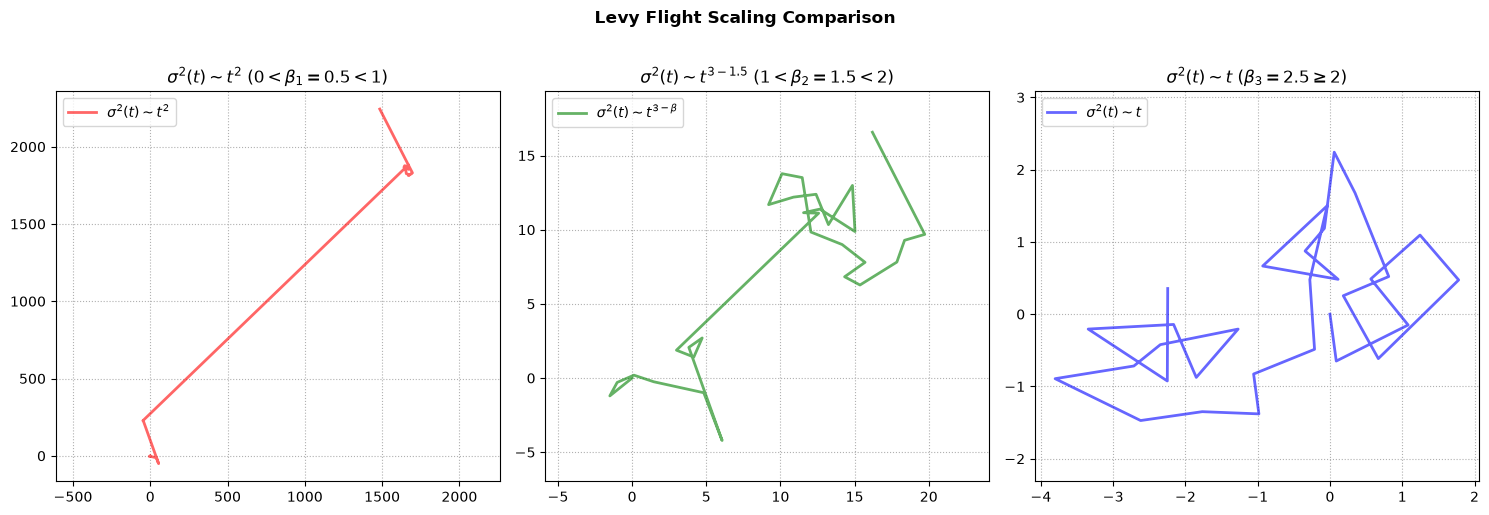

In [1]:
# ANA670 - Week 3 HW - Q2.1
import numpy as np
import matplotlib.pyplot as plt

steps, s0 = 30, 1.0
beta_1 = 0.5
beta_2 = 1.5
beta_3 = 2.5

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
regimes = [
    (beta_1, 'r', r'$\sigma^2(t) \sim t^2$', r'$\sigma^2(t) \sim t^2$ ($0 < \beta_1 = ' + str(beta_1) + r' < 1$)'),
    (beta_2, 'g', r'$\sigma^2(t) \sim t^{3-\beta}$', r'$\sigma^2(t) \sim t^{3-' + str(beta_2) + r'}$ ($1 < \beta_2 = ' + str(beta_2) + r' < 2$)'),
    (beta_3, 'b', r'$\sigma^2(t) \sim t$', r'$\sigma^2(t) \sim t$ ($\beta_3 = ' + str(beta_3) + r' \geq 2$)')
]

for ax, (beta, color, eq, title) in zip(axes, regimes):
    np.random.seed(42)
    u = np.random.uniform(0, 1, steps)
    s = np.random.normal(s0, 0.3, steps) if beta >= 2 else s0 / (u ** (1 / beta))
    angles = np.random.uniform(0, 2 * np.pi, steps)
    dx, dy = s * np.cos(angles), s * np.sin(angles)
    x = np.cumsum(np.insert(dx, 0, 0))
    y = np.cumsum(np.insert(dy, 0, 0))

    ax.plot(x, y, color=color, alpha=0.6, linewidth=2, label=eq)
    ax.set_title(title); ax.axis('equal'); ax.grid(True, linestyle=':'); ax.legend(loc='upper left')

plt.suptitle('Levy Flight Scaling Comparison', fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

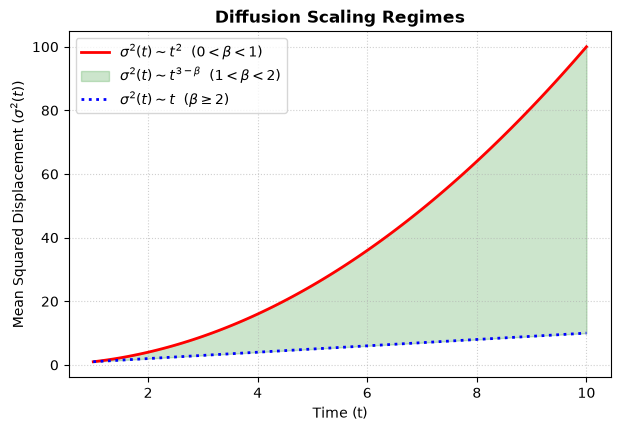

In [2]:
# ANA670 - Week 3 HW - Q2.2
t = np.linspace(1, 10, 100)
y_upper, y_lower = t**2, t

plt.figure(figsize=(7, 4.5))
plt.plot(t, y_upper, 'r-', linewidth=2, label=r'$\sigma^2(t) \sim t^2$  ($0 < \beta < 1$)')
plt.fill_between(t, y_lower, y_upper, color='g', alpha=0.2, label=r'$\sigma^2(t) \sim t^{3-\beta}$  ($1 < \beta < 2$)')
plt.plot(t, y_lower, 'b:', linewidth=2, label=r'$\sigma^2(t) \sim t$  ($\beta \geq 2$)')

plt.title('Diffusion Scaling Regimes', fontweight='bold')
plt.xlabel('Time (t)')
plt.ylabel(r'Mean Squared Displacement ($\sigma^2(t))$')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper left')
plt.show()

Average Final Distance from Origin : 88.34 units
Max Distance Reached by any Path   : 253.40 units
Theoretical RMS Distance (√N)      : 100.00 units
Theoretical Mean Distance          : 88.62 units


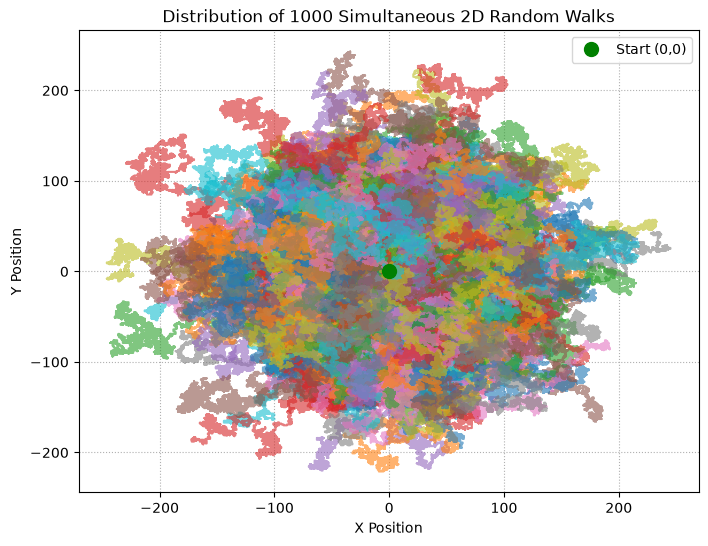

In [3]:
# ANA670 - Week 3 HW - Q3
np.random.seed(42)
num_walks = 1000
num_steps = 10000
choices = np.random.randint(0, 4, size=(num_steps, num_walks))
moves_map = np.array([[0, 1], [0, -1], [1, 0], [-1, 0]])
steps = moves_map[choices]

walks = np.zeros((num_steps + 1, num_walks, 2))
walks[1:] = np.cumsum(steps, axis=0)

final_positions = walks[-1]
distances = np.sqrt(final_positions[:, 0]**2 + final_positions[:, 1]**2)

print(f"Average Final Distance from Origin : {np.mean(distances):.2f} units")
print(f"Max Distance Reached by any Path   : {np.max(distances):.2f} units")
print(f"Theoretical RMS Distance (√N)      : {np.sqrt(num_steps):.2f} units")
print(f"Theoretical Mean Distance          : {np.sqrt(num_steps) * (np.sqrt(np.pi) / 2):.2f} units")


plt.figure(figsize=(8, 6))
for i in range(num_walks):
    plt.plot(walks[:, i, 0], walks[:, i, 1], alpha=0.6)

plt.plot(0, 0, 'go', markersize=10, label='Start (0,0)')
plt.title(f"Distribution of {num_walks} Simultaneous 2D Random Walks")
plt.xlabel("X Position"); plt.ylabel("Y Position"); plt.grid(True, linestyle=":")
plt.legend()
plt.show()

Unoptimized (OLS): y = 0.1102 - 1.1284*x^1 + 0.0283*x^2 + 0.5203*x^3 - 0.0703*x^4 - 0.0076*x^5 + 0.0106*x^6 | MSE: 0.0369
L1 (Lasso): y = 0.0434*x^5 - 0.0030*x^6 | MSE: 0.2373
L2 (Ridge): y = 0.1056 - 0.7304*x^1 + 0.0091*x^2 + 0.1823*x^3 - 0.0528*x^4 + 0.0537*x^5 + 0.0074*x^6 | MSE: 0.0486


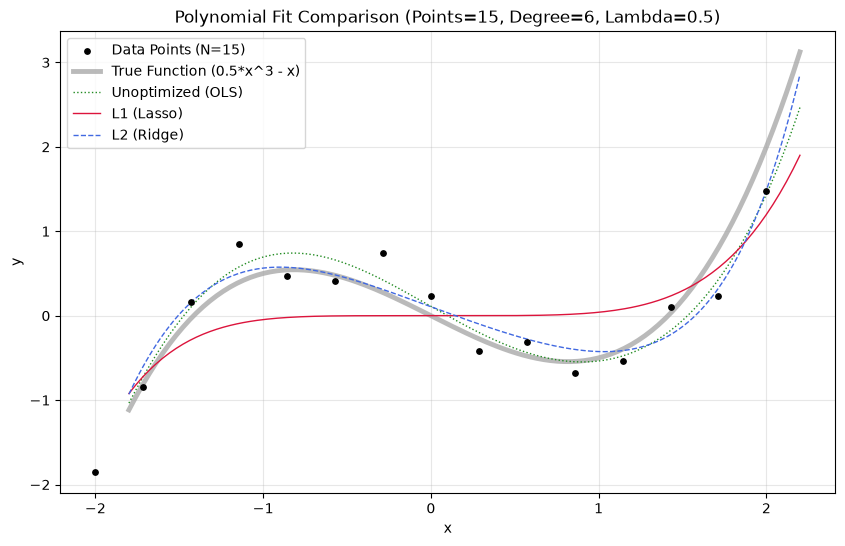

In [4]:
# ANA670 - Week 3 HW - Q4
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error

np.random.seed(42)
noise = 0.3
n_points = 15
rng = 2
X = np.linspace(-rng, rng, n_points).reshape(-1, 1)
y = (0.5 * X**3 - X + np.random.normal(0, noise, size=X.shape)).flatten()
degree = 6
lam = 0.5

fits = {
    'Unoptimized (OLS)': LinearRegression(fit_intercept=False),
    'L1 (Lasso)': Lasso(alpha=lam, fit_intercept=False, max_iter=50000, tol=1e-2),
    'L2 (Ridge)': Ridge(alpha=lam, fit_intercept=False, solver='svd')
}

def fmt_eq(c):
    t = []
    if abs(c[0]) > 1e-4: t.append(f"{c[0]:.4f}")
    for i in range(1, len(c)):
        if abs(c[i]) > 1e-4:
            s = " + " if c[i] > 0 else " - "
            v = abs(c[i])
            if not t: t.append(f"{'-' if s == ' - ' else ''}{v:.4f}*x^{i}")
            else: t.append(f"{s.strip()} {v:.4f}*x^{i}")
    return "y = " + " ".join(t) if t else "y = 0.0000"

X_pl = np.linspace(-rng+0.2, rng+0.2, 200).reshape(-1, 1)
y_true = 0.5 * X_pl**3 - X_pl
plt.figure(figsize=(10, 6))
plt.scatter(X, y, color='black', s=15, zorder=5, label=f'Data Points (N={n_points})')
plt.plot(X_pl, y_true, color='darkgray', linestyle='-', linewidth=3.5, alpha=0.8, label='True Function (0.5*x^3 - x)')

colors, styles = ['forestgreen', 'crimson', 'royalblue'], [':', '-', '--']
for (name, model), color, style in zip(fits.items(), colors, styles):
    pipe = make_pipeline(PolynomialFeatures(degree, include_bias=True), model).fit(X, y)
    c = pipe.named_steps[model.__class__.__name__.lower()].coef_
    mse = mean_squared_error(y, pipe.predict(X))
    print(f"{name}: {fmt_eq(c)} | MSE: {mse:.4f}")
    plt.plot(X_pl, pipe.predict(X_pl), color=color, linestyle=style, linewidth=1, label=name)
    
plt.title(f'Polynomial Fit Comparison (Points={n_points}, Degree={degree}, Lambda={lam})')
plt.xlabel('x'); plt.ylabel('y'); plt.grid(True, alpha=0.3); plt.legend()
plt.show()

Assumptions:
> $\text{minimize } \boldsymbol{f}(\boldsymbol{x}) = (f_1(\boldsymbol{x}), \dots, f_p(\boldsymbol{x}))$ \
> $\text{subject to } \sum_{i=1}^{n} x_i^2 \le n^2$ \
> $f_i(\boldsymbol{x}) = x_i^2 + |x_{i+1}| \quad (i = 1, 2, \dots, p-1), \qquad f_p(\boldsymbol{x}) = x_p^2 + |x_1|$ \
> $-n \le x_i \le n$

$F(x) = w_1 f_1(x) + w_2 f_2(x) + \dots + w_p f_p(x)$ \
$F(x) = \sum_{j=1}^{p} w_j f_j(x)$

The weighted sum method can be used to create a master function ($F(x)$) by multiplying each individual function ($f_i$) by a pre-determined weight. In this particular example, the optimal solution will not change with weights. Because it has squares ($x^2$) and absolute values ($|x|$) the minimum cost will be zero. Setting all variables to zero ($x=0$) minimizes the equation regardless of weights.

=== 3D SURFACE PLOT DATA ===
Fixed Weights Used: [0.5 0.3 0.2]
Theoretical Global Minimum: x = 0, F(x) = 0

=== MULTI-VARIABLE VERIFICATION DATA (First 5 Trials) ===
Trial 1:
  Random Weights: [0.229 0.027 0.558 0.133 0.052]
  Resulting Knobs (x): [-0. -0. -0. -0. -0.]
  Achieved Cost F(x): 0.0000000
Trial 2:
  Random Weights: [0.257 0.17  0.005 0.356 0.213]
  Resulting Knobs (x): [-0. -0. -0.  0. -0.]
  Achieved Cost F(x): 0.0000000
Trial 3:
  Random Weights: [0.279 0.38  0.079 0.179 0.083]
  Resulting Knobs (x): [-0. -0. -0. -0. -0.]
  Achieved Cost F(x): 0.0000000
Trial 4:
  Random Weights: [0.252 0.135 0.118 0.277 0.218]
  Resulting Knobs (x): [-0. -0. -0. -0. -0.]
  Achieved Cost F(x): 0.0000000
Trial 5:
  Random Weights: [0.217 0.157 0.17  0.28  0.176]
  Resulting Knobs (x): [ 0. -0. -0. -0. -0.]
  Achieved Cost F(x): 0.0000000


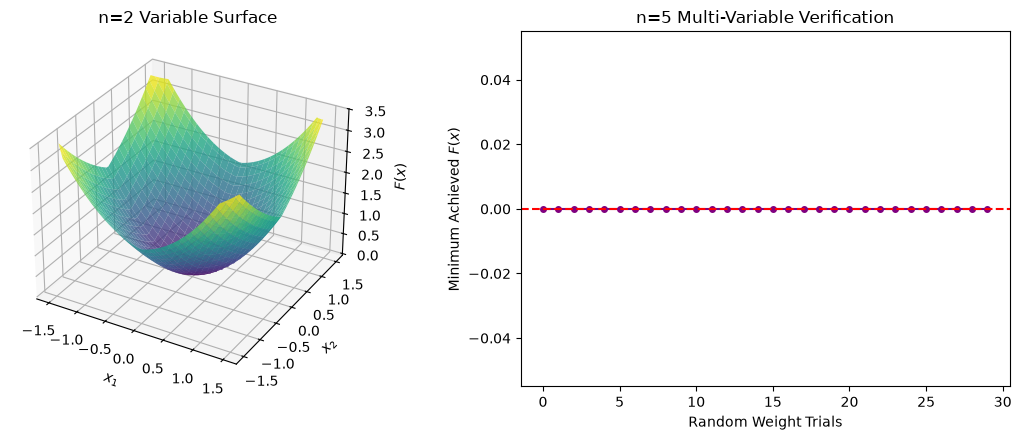

In [5]:
# ANA670 - Week 3 HW - Q5
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import minimize

w_3d = np.array([0.5, 0.3, 0.2])
print("=== 3D SURFACE PLOT DATA ===")
print(f"Fixed Weights Used: {w_3d}\nTheoretical Global Minimum: x = 0, F(x) = 0\n")

r = np.linspace(-1.5, 1.5, 60)
X1, X2 = np.meshgrid(r, r)
Z = np.zeros_like(X1)

for i in range(3): Z += w_3d[i] * (X1**2 + np.abs(X2) if i % 2 == 0 else X2**2 + np.abs(X1))

Z[X1**2 + X2**2 > 4] = np.nan
fig = plt.figure(figsize=(11, 4.5))
ax1 = fig.add_subplot(1, 2, 1, projection="3d")
ax1.plot_surface(X1, X2, Z, cmap="viridis", alpha=0.8, edgecolor="none")
ax1.set_xlabel("$x_1$"); ax1.set_ylabel("$x_2$"); ax1.set_zlabel("$F(x)$"); ax1.set_title("n=2 Variable Surface")

n, p = 5, 5
obj = lambda x, w: sum(w[i] * (x[i % n] ** 2 + np.abs(x[(i + 1) % n])) for i in range(p))
vals = []

print("=== MULTI-VARIABLE VERIFICATION DATA (First 5 Trials) ===")
for trial in range(30):
    w = np.random.rand(p); w_norm = w / w.sum()
    res = minimize(obj, np.random.uniform(-1, 1, n), args=(w_norm,), method="SLSQP", bounds=[(-n, n)] * n, constraints={"type": "ineq", "fun": lambda x: n**2 - np.sum(x**2)}, tol=1e-12)
    final_score = res.fun if res.fun > 1e-7 else 0.0
    vals.append(final_score)
    if trial < 5:
        print(f"Trial {trial+1}:")
        print(f"  Random Weights: {np.round(w_norm, 3)}\n  Resulting Knobs (x): {np.round(res.x, 5)}\n  Achieved Cost F(x): {res.fun:.7f}")

ax2 = fig.add_subplot(1, 2, 2)
ax2.plot(vals, "o-", color="purple", markersize=4); ax2.axhline(0, color="red", linestyle="--")
ax2.set_xlabel("Random Weight Trials"); ax2.set_ylabel("Minimum Achieved $F(x)$"); ax2.set_title("n=5 Multi-Variable Verification")
plt.tight_layout(); plt.show()

Assumptions:
> $f_1 = x_1$ \
> $f_2 = g \times h$ \
> $h = 1 - \sqrt{\frac{f_1}{g}}$ \
> $g = 1 + 9 \sum_{i=2}^{n} \frac{x_i}{(n-1)} = 1$

$h = 1 - \sqrt{\frac{f_1}{g}} = 1 - \sqrt{\frac{f_1}{1}} = 1 - \sqrt{f_1}$ \
$f_2 = 1 - \sqrt{f_1}$

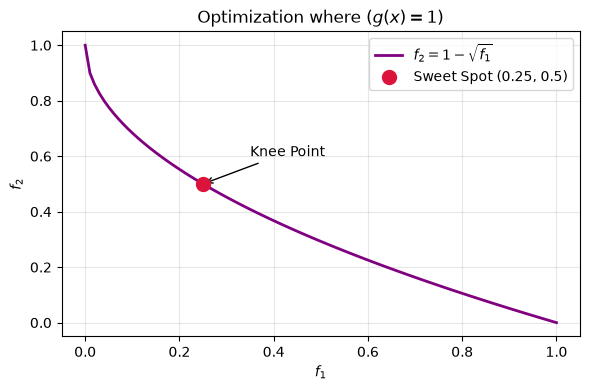

In [6]:
# ANA670 - Week 3 HW - Q6
import sympy as sp
f1_s = sp.Symbol("f1"); f2_s = 1 - sp.sqrt(f1_s)
kf1 = float(sp.solve(sp.Eq(sp.diff(f2_s, f1_s), -1), f1_s)[0]); kf2 = float(f2_s.subs(f1_s, kf1))
f1 = np.linspace(0, 1, 100); f2 = 1 - np.sqrt(f1)

plt.figure(figsize=(6, 4))
plt.plot(f1, f2, color="purple", lw=2, label=r"$f_2 = 1 - \sqrt{f_1}$")
plt.scatter(kf1, kf2, color="crimson", s=100, zorder=5, label=f"Sweet Spot ({kf1}, {kf2})")
plt.annotate("Knee Point", xy=(kf1, kf2), xytext=(kf1+0.1, kf2+0.1), arrowprops=dict(arrowstyle="->"))
plt.xlabel("$f_1$"); plt.ylabel("$f_2$"); plt.title("Optimization where ($g(x)=1$)")
plt.grid(True, alpha=0.3); plt.legend(); plt.tight_layout(); plt.show()